# 04 M2: deep hedging with proportional costs (GBM)
Quadratic vs entropic loss, plain MLP vs no-transaction-band network, compared with BS delta and the Whalley-Wilmott band.

In [1]:
# notebooks live in notebooks/, the project modules in the repo root
import sys
if '..' not in sys.path:
    sys.path.insert(0, '..')

%load_ext autoreload
%autoreload 2

# standard libraries
import math

# third-party
import numpy as np
import pandas as pd
import torch
import seaborn as sns
from matplotlib import pyplot as plt

# project modules
import benchmarks as bm
from model import Policy
from market.simulators import simulate_heston, simulate_gbm, HestonParams
from market.pricing import bs_price, bs_delta, bs_gamma, heston_price
from features import nn_policy, ntb_policy
from train import train
from objectives import EntropicLoss


In [2]:
# shared constants of the M2 experiments (in scratch they came from earlier cells)
K, T, sigma, c = 100.0, 30 / 365, 0.2, 0.001


*Helper functions: test set, evaluation table (NN + BS + WW grid), band plot.*

In [4]:
def make_test_set(seed=None, n_paths=100_000):
    """GBM test paths (B, n+1). Fix `seed` to evaluate every model on the same paths."""
    if seed is not None:
        torch.manual_seed(seed)
    return simulate_gbm(n_paths)["S"][:, :, 0]


def eval_table(nn_pols, S_test, price="entropic", lam=1.0):
    """Evaluate the given network policies + BS delta + WW band (gamma grid) on S_test.

    price = "quadratic": premium p0 = -mean(PnL)              (column "p0")
    price = "entropic":  premium rho = entropic risk of PnL   (column "rho")
    Remaining columns: summary of the P&L including that premium.
    """
    ent = EntropicLoss(lam)
    pols = {**nn_pols, "BS": bm.bs_delta_policy(K, sigma)}
    pols.update({f"WW γ={g:.2g}": bm.ww_band_policy(K, sigma, c, g) for g in np.logspace(-1, 2, 10)})

    rows = {}
    with torch.no_grad():
        for name, pol in pols.items():
            pnl = bm.hedge_pnl(S_test, pol, K, T, c=c)          # p0 = 0
            if price == "quadratic":
                rows[name] = {"p0": -pnl.mean().item()}
            else:
                rows[name] = {"rho": ent(pnl).item()}
            p0 = next(iter(rows[name].values()))
            rows[name].update(bm.summarize(pnl + p0))
    return pd.DataFrame(rows).T


def band_plot(nn_pols, S_fix=100.0, tau_fix=15 / 365):
    """Plot delta_k vs delta_{k-1} at fixed (S, tau) for the given policies, plus WW (gamma = 10)
    and BS delta. The diagonal delta_k = delta_{k-1} means no trade."""
    dp_grid = torch.linspace(0.3, 0.8, 200)
    S_vec = torch.full_like(dp_grid, S_fix)
    pols = {name: (pol, "-") for name, pol in nn_pols.items()}
    pols["WW γ=10"] = (bm.ww_band_policy(K, sigma, c, 10.0), "--")
    pols["BS delta"] = (bm.bs_delta_policy(K, sigma), ":")

    fig, ax = plt.subplots(figsize=(6, 6))
    with torch.no_grad():
        for name, (pol, ls) in pols.items():
            ax.plot(dp_grid, pol(S_vec, tau_fix, dp_grid), ls=ls, label=name)
    ax.plot(dp_grid, dp_grid, lw=0.8, color="black", alpha=0.4, label="no trade (δ = δ_prev)")
    ax.set_xlabel(r"$\delta_{k-1}$")
    ax.set_ylabel(r"$\delta_k$")
    ax.set_title(f"S = {S_fix:.0f}, τ = {tau_fix * 365:.0f}d")
    ax.legend()
    plt.show()

## With cost, NN and WW_delta

*M2 with quadratic loss: Policy(3, 1) with delta_prev as a feature, c = 0.001.*

In [ ]:
## quadratic loss
model2 = Policy(d_in=3, m_out=1)
out2 = train(model2, K, T, c=c, use_prev=True, n_steps=3000)

step: 0, loss: 16.748985290527344, p0: 0.0
step: 100, loss: 4.734732151031494, p0: 0.9259551167488098
step: 200, loss: 1.238590955734253, p0: 1.6122369766235352
step: 300, loss: 0.560280978679657, p0: 2.0608913898468018
step: 400, loss: 0.3215180039405823, p0: 2.3090176582336426
step: 500, loss: 0.2682272493839264, p0: 2.4303157329559326
step: 600, loss: 0.2232307642698288, p0: 2.487492322921753
step: 700, loss: 0.20952042937278748, p0: 2.5169689655303955
step: 800, loss: 0.19767136871814728, p0: 2.5309677124023438
step: 900, loss: 0.1873152256011963, p0: 2.5381298065185547
step: 1000, loss: 0.1775292307138443, p0: 2.543278694152832
step: 1100, loss: 0.16705644130706787, p0: 2.546475887298584
step: 1200, loss: 0.1635948121547699, p0: 2.548957586288452
step: 1300, loss: 0.16044840216636658, p0: 2.549281120300293
step: 1400, loss: 0.15727367997169495, p0: 2.5509350299835205
step: 1500, loss: 0.15672089159488678, p0: 2.5514135360717773
step: 1600, loss: 0.1532447338104248, p0: 2.550627231

*Quadratic-loss evaluation (price = -mean): NN ~ BS, every WW is worse on std -- quadratic loss ignores mean costs.*

In [ ]:
eval_table({"NN": nn_policy(model2, K, T, use_prev=True)}, make_test_set(), price="quadratic")

,p0,mean,std,VaR,CVaR
NN,2.553447,2.105713e-08,0.377752,0.621331,0.879572
BS,2.559462,1.152802e-07,0.377128,0.651221,0.922728
WW γ=0.1,2.425987,-3.280640e-08,0.876150,1.415043,1.712337
WW γ=0.22,2.433692,1.193237e-07,0.740232,1.167892,1.465900
WW γ=0.46,2.442412,-9.902954e-08,0.638350,0.992196,1.294226
WW γ=1,2.452063,-3.211975e-08,0.562260,0.876290,1.172333
WW γ=2.2,2.462712,1.635742e-07,0.505775,0.801142,1.084523
WW γ=4.6,2.473937,1.325226e-07,0.464390,0.747774,1.020275
WW γ=10,2.485335,-1.026535e-07,0.434595,0.705565,0.974983
WW γ=22,2.496474,1.774979e-07,0.413987,0.681244,0.945540


*M2 with the entropic loss (lambda = 1), which penalizes mean costs and risk together.*

In [41]:
## Entropic Loss
model3 = Policy(d_in=3, m_out=1)
out3 = train(model3, K, T, loss_fn=EntropicLoss(1.0), c=c, use_prev=True, n_steps=3000)

step: 0, loss: 12.863698959350586
step: 100, loss: 4.103878021240234
step: 200, loss: 2.7290515899658203
step: 300, loss: 2.6581315994262695
step: 400, loss: 2.672727584838867
step: 500, loss: 2.6557769775390625
step: 600, loss: 2.628824234008789
step: 700, loss: 2.6271190643310547
step: 800, loss: 2.6114463806152344
step: 900, loss: 2.6114730834960938
step: 1000, loss: 2.630565643310547
step: 1100, loss: 2.6273365020751953
step: 1200, loss: 2.6035308837890625
step: 1300, loss: 2.6110334396362305
step: 1400, loss: 2.629871368408203
step: 1500, loss: 2.605158805847168
step: 1600, loss: 2.6000747680664062
step: 1700, loss: 2.602294921875
step: 1800, loss: 2.6066226959228516
step: 1900, loss: 2.6068267822265625
step: 2000, loss: 2.6132030487060547
step: 2100, loss: 2.6043128967285156
step: 2200, loss: 2.600679397583008
step: 2300, loss: 2.5965375900268555
step: 2400, loss: 2.5970611572265625
step: 2500, loss: 2.6020565032958984
step: 2600, loss: 2.6053619384765625
step: 2700, loss: 2.5959

*Entropic evaluation: price rho for NN, BS and a grid of WW gamma.*

In [42]:
eval_table({"NN": nn_policy(model3, K, T, use_prev=True)}, make_test_set())

,rho,mean,std,VaR,CVaR
NN,2.594753,0.101328,0.449987,0.593259,0.835566
BS,2.638491,0.078174,0.378308,0.577827,0.847514
WW γ=0.1,2.801904,0.378391,0.876011,1.033064,1.342102
WW γ=0.22,2.702469,0.270323,0.740726,0.895107,1.201691
WW γ=0.46,2.644282,0.203486,0.640142,0.791770,1.096670
WW γ=1,2.610783,0.160167,0.564535,0.721944,1.017332
WW γ=2.2,2.592685,0.131211,0.507861,0.674993,0.957663
WW γ=4.6,2.584987,0.111921,0.466330,0.639264,0.913082
WW γ=10,2.583864,0.099161,0.436648,0.613301,0.880712
WW γ=22,2.586892,0.090759,0.415884,0.595807,0.859290


*Extra training of model3 at lr = 1e-4 (continues from the current weights).*

In [43]:
## Extra training on model3
out3b = train(model3, K, T, loss_fn=EntropicLoss(1.0), c=c, use_prev=True,
              lr=1e-4, n_steps=2000)

step: 0, loss: 2.5865116119384766
step: 100, loss: 2.5960159301757812
step: 200, loss: 2.6064605712890625
step: 300, loss: 2.6031036376953125
step: 400, loss: 2.593626022338867
step: 500, loss: 2.592616081237793
step: 600, loss: 2.5957870483398438
step: 700, loss: 2.597126007080078
step: 800, loss: 2.6034746170043945
step: 900, loss: 2.589824676513672
step: 1000, loss: 2.5873451232910156
step: 1100, loss: 2.5983638763427734
step: 1200, loss: 2.589801788330078
step: 1300, loss: 2.593210220336914
step: 1400, loss: 2.5847434997558594
step: 1500, loss: 2.6000938415527344
step: 1600, loss: 2.592336654663086
step: 1700, loss: 2.580667495727539
step: 1800, loss: 2.5887928009033203
step: 1900, loss: 2.591592788696289


*Re-evaluation after extra training (different test seed, compare gaps not levels).*

In [47]:
eval_table({"NN": nn_policy(model3, K, T, use_prev=True)}, make_test_set())

,rho,mean,std,VaR,CVaR
NN,2.596223,0.097191,0.440337,0.592887,0.831750
BS,2.639782,0.077000,0.375957,0.573623,0.837202
WW γ=0.1,2.807323,0.377456,0.874675,1.037352,1.341097
WW γ=0.22,2.707546,0.268821,0.738742,0.896774,1.203448
WW γ=0.46,2.649606,0.201732,0.637672,0.795944,1.100670
WW γ=1,2.616066,0.158531,0.561963,0.724924,1.022208
WW γ=2.2,2.597773,0.129891,0.505563,0.674005,0.961179
WW γ=4.6,2.589368,0.110720,0.464052,0.635987,0.913155
WW γ=10,2.587426,0.097908,0.434274,0.610579,0.878157
WW γ=22,2.589789,0.089502,0.413502,0.596299,0.855354


*Band plot delta_k vs delta_{k-1} at S = 100, tau = 15d: the MLP learns partial adjustment, not a band.*

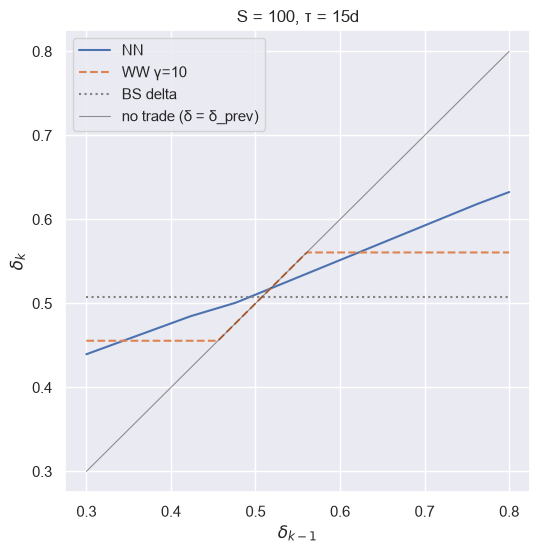

In [48]:
band_plot({"NN": nn_policy(model3, K, T, use_prev=True)})

*model4: same as model3 but with normalized log-moneyness (s_scale = sigma sqrt(T)).*

In [ ]:
## model 4, changed the scale of log(S/K) so that matches tau_k and delta_prev
s_scale = sigma * (T ** 0.5)      # ≈ 0.057

model4 = Policy(d_in=3, m_out=1)
out4 = train(model4, K, T, loss_fn=EntropicLoss(1.0), c=c,
             use_prev=True, s_scale=s_scale, n_steps=3000)

step: 0, loss: 14.691518783569336
step: 100, loss: 2.665513038635254
step: 200, loss: 2.6031808853149414
step: 300, loss: 2.602365493774414
step: 400, loss: 2.5914974212646484
step: 500, loss: 2.6066646575927734
step: 600, loss: 2.6117897033691406
step: 700, loss: 2.585348129272461
step: 800, loss: 2.5958023071289062
step: 900, loss: 2.596787452697754
step: 1000, loss: 2.582307815551758
step: 1100, loss: 2.5961380004882812
step: 1200, loss: 2.5855579376220703
step: 1300, loss: 2.5916881561279297
step: 1400, loss: 2.599233627319336
step: 1500, loss: 2.5880565643310547
step: 1600, loss: 2.5960559844970703
step: 1700, loss: 2.594217300415039
step: 1800, loss: 2.5870046615600586
step: 1900, loss: 2.5912113189697266
step: 2000, loss: 2.5893020629882812
step: 2100, loss: 2.574453353881836
step: 2200, loss: 2.590747833251953
step: 2300, loss: 2.588235855102539
step: 2400, loss: 2.5921859741210938
step: 2500, loss: 2.593748092651367
step: 2600, loss: 2.5807037353515625
step: 2700, loss: 2.5848

*Entropic evaluation of model4 (faster convergence, gap to best WW shrinks slightly).*

In [52]:
eval_table({"NN": nn_policy(model4, K, T, use_prev=True, s_scale=s_scale)}, make_test_set(seed=9))

,rho,mean,std,VaR,CVaR
NN,2.591479,0.095365,0.435382,0.596452,0.825265
BS,2.639827,0.077453,0.375937,0.573642,0.844059
WW γ=0.1,2.809981,0.378712,0.875820,1.035048,1.344706
WW γ=0.22,2.708987,0.270311,0.739777,0.899730,1.206617
WW γ=0.46,2.650113,0.203040,0.638468,0.792363,1.102138
WW γ=1,2.615649,0.159206,0.562115,0.719964,1.021147
WW γ=2.2,2.596953,0.130277,0.505422,0.668569,0.959926
WW γ=4.6,2.588961,0.111092,0.463933,0.633403,0.915850
WW γ=10,2.587438,0.098309,0.434127,0.608566,0.883906
WW γ=22,2.589900,0.089922,0.413333,0.591675,0.861377


*Band plot for model4: still partial adjustment.*

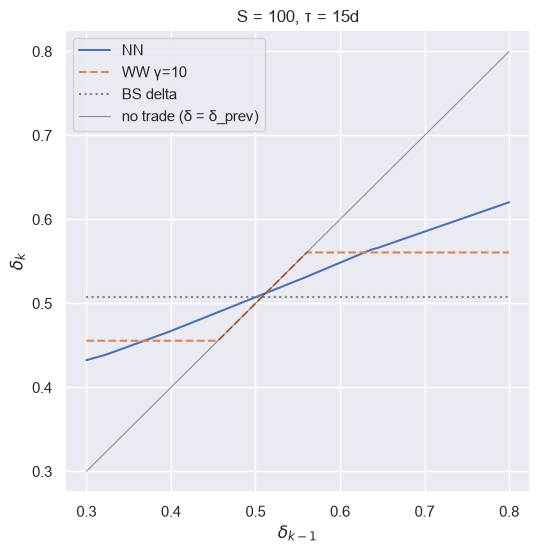

In [56]:
band_plot({"NN": nn_policy(model4, K, T, use_prev=True, s_scale=s_scale)})

> **TODO (Micky):** fully understand the NTB policy -- why imposing the band structure helps, the softplus widths around the BS delta, the bias initialization at -3, and where the gradient flows through the clamp. See `features.ntb_policy`.

*No-transaction-band network: outputs two band widths around the BS delta, position = clamp(delta_prev).*

In [58]:
model5 = Policy(d_in=2, m_out=2)
with torch.no_grad():
    model5.net[-1].bias.fill_(-3.0)     ## advoid the initial gradient to be 0

pol_ntb = ntb_policy(model5, K, T, sigma, s_scale)
out5 = train(model5, K, T, loss_fn=EntropicLoss(1.0), c=c,
             policy=pol_ntb, n_steps=3000)

step: 0, loss: 2.5797338485717773
step: 100, loss: 2.5848560333251953
step: 200, loss: 2.5804624557495117
step: 300, loss: 2.587265968322754
step: 400, loss: 2.5678625106811523
step: 500, loss: 2.579446792602539
step: 600, loss: 2.574822425842285
step: 700, loss: 2.5732288360595703
step: 800, loss: 2.575603485107422
step: 900, loss: 2.5829429626464844
step: 1000, loss: 2.587392807006836
step: 1100, loss: 2.5834388732910156
step: 1200, loss: 2.5762100219726562
step: 1300, loss: 2.589946746826172
step: 1400, loss: 2.5698814392089844
step: 1500, loss: 2.569234848022461
step: 1600, loss: 2.581045150756836
step: 1700, loss: 2.572072982788086
step: 1800, loss: 2.5798559188842773
step: 1900, loss: 2.5758790969848633
step: 2000, loss: 2.566086769104004
step: 2100, loss: 2.572585105895996
step: 2200, loss: 2.5818252563476562
step: 2300, loss: 2.5832366943359375
step: 2400, loss: 2.5661725997924805
step: 2500, loss: 2.5868358612060547
step: 2600, loss: 2.571343421936035
step: 2700, loss: 2.58685

*Final M2 table on one fixed test set: MLP, NTB, BS, WW grid -- NTB beats the best WW.*

In [59]:
eval_table({"NN (MLP)": nn_policy(model4, K, T, use_prev=True, s_scale=s_scale),
            "NN (NTB)": pol_ntb},
           make_test_set(seed=0))

,rho,mean,std,VaR,CVaR
NN (MLP),2.588416,0.095483,0.437044,0.597238,0.816912
NN (NTB),2.575355,0.097883,0.445128,0.585619,0.810810
BS,2.637115,0.077312,0.376556,0.575298,0.842512
WW γ=0.1,2.803138,0.379211,0.877568,1.035942,1.343026
WW γ=0.22,2.702792,0.269392,0.740880,0.897994,1.198593
WW γ=0.46,2.644262,0.201089,0.638158,0.796344,1.088986
WW γ=1,2.610982,0.157553,0.561688,0.722465,1.006365
WW γ=2.2,2.593171,0.129219,0.505286,0.669807,0.947461
WW γ=4.6,2.585219,0.110391,0.463999,0.635331,0.904232
WW γ=10,2.583854,0.097906,0.434452,0.609125,0.873912


*Band plot of MLP, NTB, WW and BS on one figure.*

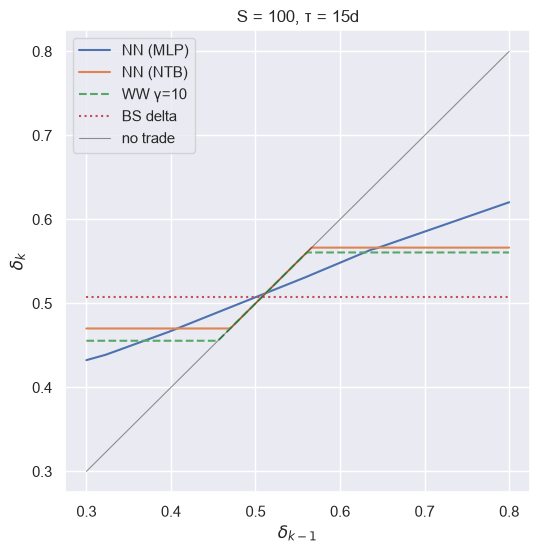

In [60]:
band_plot({"NN (MLP)": nn_policy(model4, K, T, use_prev=True, s_scale=s_scale),
           "NN (NTB)": pol_ntb})

*Compatibility check after generalizing `hedge_pnl` to several instruments: BS and WW rows must equal the table above exactly (same seed).*